## Load data and prepare a holdout split

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR
from sklearn.metrics import accuracy_score, classification_report, mean_absolute_error, mean_squared_error

df = pd.read_csv(Path("heart attack analysis.csv"))
X = df.drop(columns="output")
y = df["output"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [2]:
svc_grid = GridSearchCV(
    SVC(),
    {"kernel": ["linear", "rbf"], "C": [0.1, 1, 10], "gamma": ["scale", 0.01, 0.1]},
    cv=5, scoring="accuracy", n_jobs=-1
)
svc_grid.fit(X_train_scaled, y_train)
svc_pred = svc_grid.predict(X_test_scaled)
print("Best SVC parameters:", svc_grid.best_params_)
print("Best CV accuracy:", svc_grid.best_score_)
print("Holdout accuracy:", accuracy_score(y_test, svc_pred))
print(classification_report(y_test, svc_pred, zero_division=0))

Best SVC parameters: {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV accuracy: 0.85487922705314
Holdout accuracy: 0.7631578947368421
              precision    recall  f1-score   support

           0       0.81      0.63      0.71        35
           1       0.73      0.88      0.80        41

    accuracy                           0.76        76
   macro avg       0.77      0.75      0.75        76
weighted avg       0.77      0.76      0.76        76



In [3]:
svr_grid = GridSearchCV(
    SVR(),
    {"kernel": ["linear", "rbf"], "C": [0.1, 1, 10],
     "gamma": ["scale", 0.01, 0.1], "epsilon": [0.05, 0.2]},
    cv=5, scoring="neg_mean_squared_error", n_jobs=-1
)
svr_grid.fit(X_train_scaled, y_train.astype(float))
svr_pred = svr_grid.predict(X_test_scaled)
print("Best SVR parameters:", svr_grid.best_params_)
print("CV RMSE:", np.sqrt(-svr_grid.best_score_))
print("Holdout MAE:", mean_absolute_error(y_test, svr_pred))
print("Holdout RMSE:", np.sqrt(mean_squared_error(y_test, svr_pred)))

Best SVR parameters: {'C': 1, 'epsilon': 0.2, 'gamma': 0.01, 'kernel': 'rbf'}
CV RMSE: 0.3463055178870946
Holdout MAE: 0.31077270603862495
Holdout RMSE: 0.3982400530748844


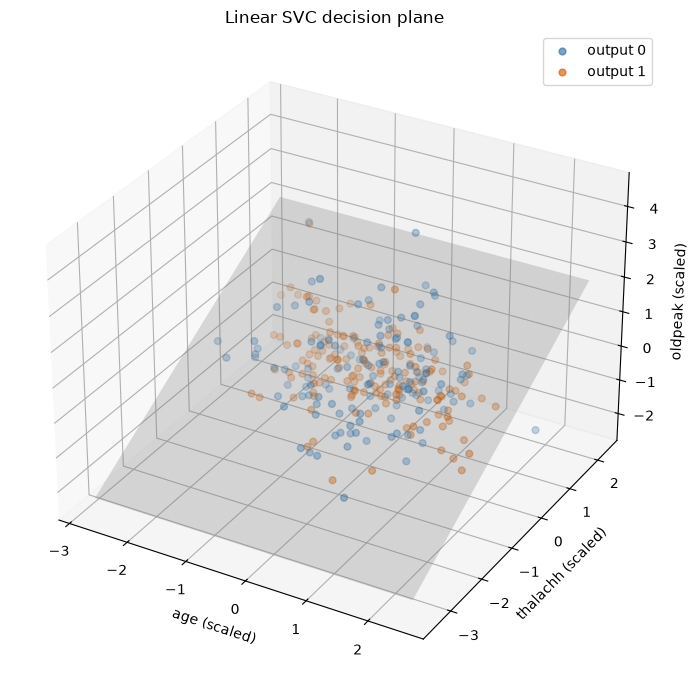

In [4]:
features_3d = ["age", "thalachh", "oldpeak"]
scaler_3d = StandardScaler().fit(X[features_3d])
X_3d = scaler_3d.transform(X[features_3d])
plane_model = SVC(kernel="linear", C=1).fit(X_3d, y)
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
for cls, label, color in [(0, "output 0", "#3572a5"), (1, "output 1", "#d55e00")]:
    mask = y.to_numpy() == cls
    ax.scatter(X_3d[mask, 0], X_3d[mask, 1], X_3d[mask, 2],
               label=label, color=color, alpha=0.65, s=24)
w = plane_model.coef_[0]
b = plane_model.intercept_[0]
xx, yy = np.meshgrid(np.linspace(X_3d[:, 0].min(), X_3d[:, 0].max(), 20),
                     np.linspace(X_3d[:, 1].min(), X_3d[:, 1].max(), 20))
if abs(w[2]) > 1e-10:
    zz = -(w[0] * xx + w[1] * yy + b) / w[2]
    ax.plot_surface(xx, yy, zz, color="gray", alpha=0.25)
ax.set_xlabel("age (scaled)"); ax.set_ylabel("thalachh (scaled)")
ax.set_zlabel("oldpeak (scaled)"); ax.set_title("Linear SVC decision plane")
ax.legend(); plt.tight_layout(); plt.show()